Размер изображения: (512, 512)
Размер изображения: (512, 512)


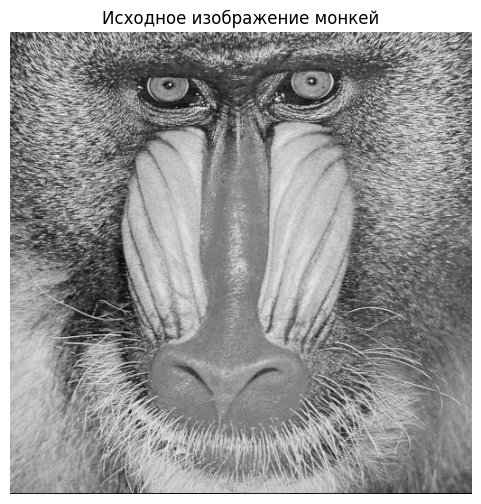

In [37]:
import numpy as np
import cv2 as cv
from matplotlib import pyplot as plt
img = cv.imread('Monkey.jpg', cv.IMREAD_GRAYSCALE)

if img is None:
    print('Ошибка: Monkey не найдена')
else:
    print('Размер изображения:', img.shape)
print('Размер изображения:', img.shape)

plt.figure(figsize=(6, 6))
plt.imshow(img, cmap='gray')
plt.title('Исходное изображение монкей')
plt.axis('off')
plt.show()


In [38]:
#Функции прямого и обратного преобразования хаара
def haar_step(a):
    p = a[0::2, 0::2]
    q = a[0::2, 1::2]
    r = a[1::2, 0::2]
    s = a[1::2, 1::2]

    ll = (p + q + r + s) / 2
    lh = (p - q + r - s) / 2
    hl = (p + q - r - s) / 2
    hh = (p - q - r + s) / 2

    n = a.shape[0] // 2
    res = np.zeros_like(a, dtype=np.float32)

    res[:n, :n] = ll
    res[:n, n:] = lh
    res[n:, :n] = hl
    res[n:, n:] = hh

    return res


def haar_inv_step(a):
    n = a.shape[0] // 2

    ll = a[:n, :n]
    lh = a[:n, n:]
    hl = a[n:, :n]
    hh = a[n:, n:]

    res = np.zeros_like(a, dtype=np.float32)

    res[0::2, 0::2] = (ll + lh + hl + hh) / 2
    res[0::2, 1::2] = (ll - lh + hl - hh) / 2
    res[1::2, 0::2] = (ll + lh - hl - hh) / 2
    res[1::2, 1::2] = (ll - lh - hl + hh) / 2

    return res


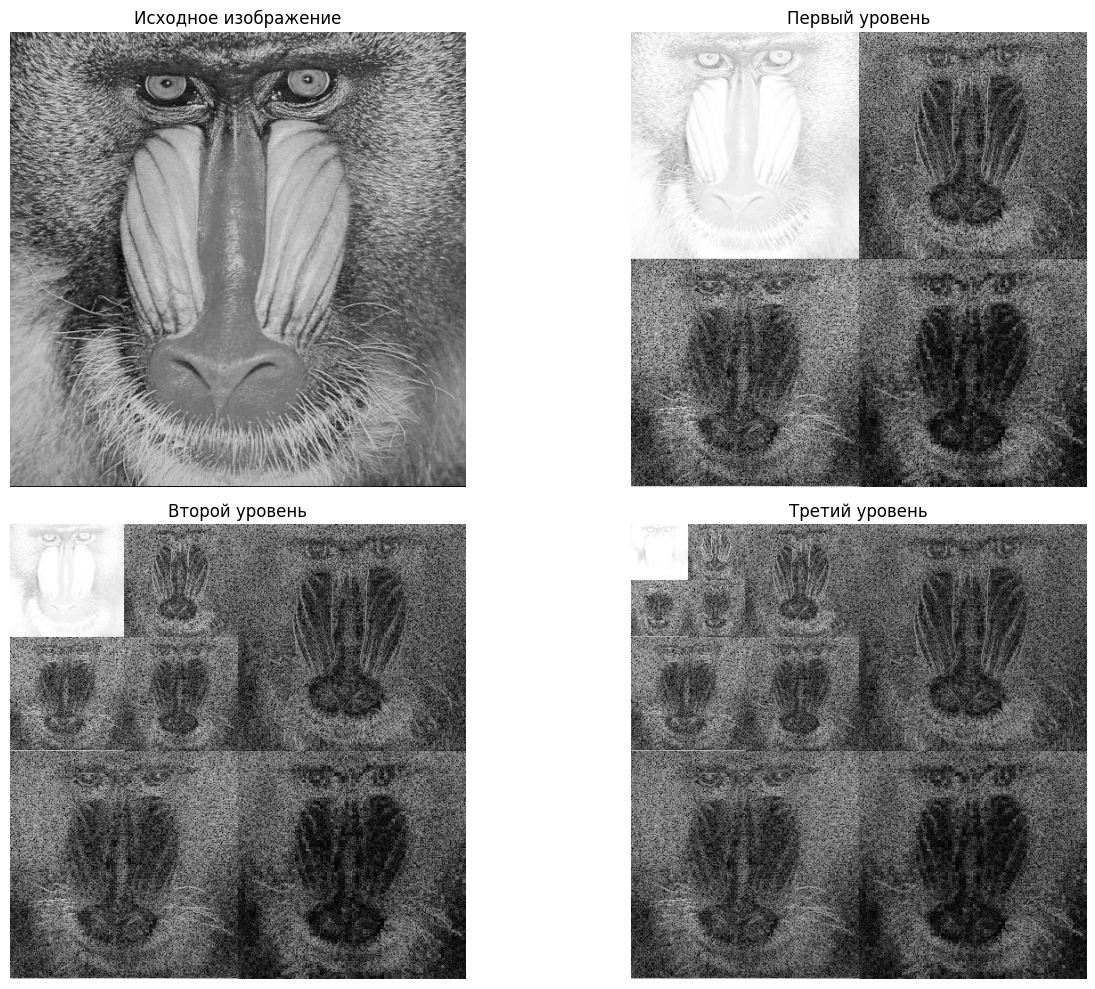

In [39]:
plt.figure(figsize=(14, 10))

for i, (c, name) in enumerate([
    (img, 'Исходное изображение'),
    (c1, 'Первый уровень'),
    (c2, 'Второй уровень'),
    (c3, 'Третий уровень')
]):
    plt.subplot(2, 2, i + 1)

    if i == 0:
        plt.imshow(c, cmap='gray', vmin=0, vmax=255)
    else:
        spec = np.log1p(np.abs(c))
        vmax = np.percentile(spec, 99)
        plt.imshow(spec, cmap='gray', vmin=0, vmax=vmax)

    plt.title(name)
    plt.axis('off')

plt.tight_layout()
plt.show()

Всего коэффициентов: 262144
Оставлено коэффициентов: 16998
Доля оставленных коэффициентов: 6.48%


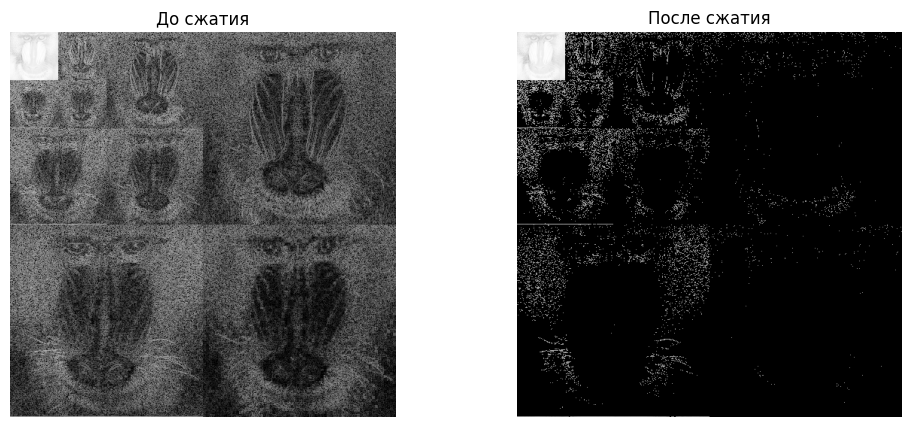

In [40]:
#Сжатие изображения
mask = np.ones(coef.shape, dtype=bool)
mask[:64, :64] = False

#Выбираем 5% самых больших детальных коэффициентов
pos = np.flatnonzero(mask)
vals = coef.ravel()[pos]

keep = int(len(vals) * 0.05)
idx = np.argpartition(np.abs(vals), -keep)[-keep:]

compressed = np.zeros_like(coef)
compressed[:64, :64] = coef[:64, :64]
compressed.ravel()[pos[idx]] = vals[idx]

print('Всего коэффициентов:', coef.size)
print('Оставлено коэффициентов:', 64 * 64 + keep)
print('Доля оставленных коэффициентов: {:.2f}%'.format(
    (64 * 64 + keep) / coef.size * 100
))

plt.figure(figsize=(12, 5))

plt.subplot(121)
plt.imshow(np.log1p(np.abs(coef)), cmap='gray')
plt.title('До сжатия')
plt.axis('off')

plt.subplot(122)
plt.imshow(np.log1p(np.abs(compressed)), cmap='gray')
plt.title('После сжатия')
plt.axis('off')

plt.show()


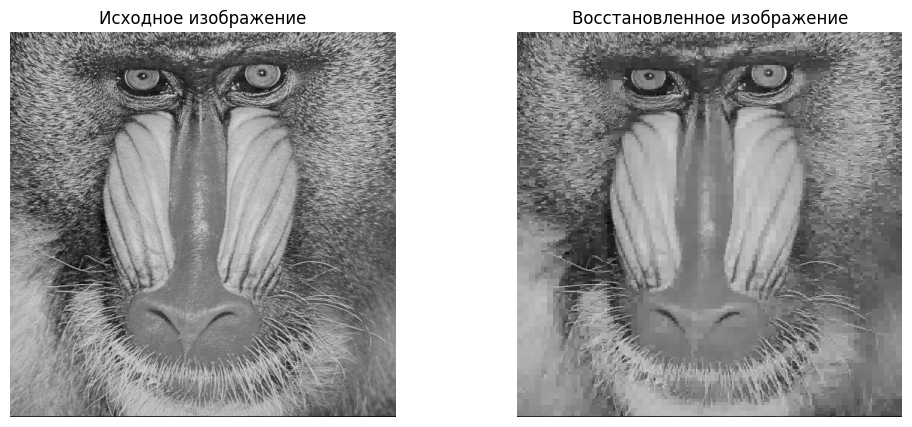

In [41]:
#Обратное преобразование
restored = compressed.copy()

for n in [128, 256, 512]:
    restored[:n, :n] = haar_inv_step(restored[:n, :n])

restored = np.clip(restored, 0, 255).astype(np.uint8)

plt.figure(figsize=(12, 5))

plt.subplot(121)
plt.imshow(img, cmap='gray', vmin=0, vmax=255)
plt.title('Исходное изображение')
plt.axis('off')

plt.subplot(122)
plt.imshow(restored, cmap='gray', vmin=0, vmax=255)
plt.title('Восстановленное изображение')
plt.axis('off')

plt.show()


MSE: 297.11
PSNR: 23.4 дБ


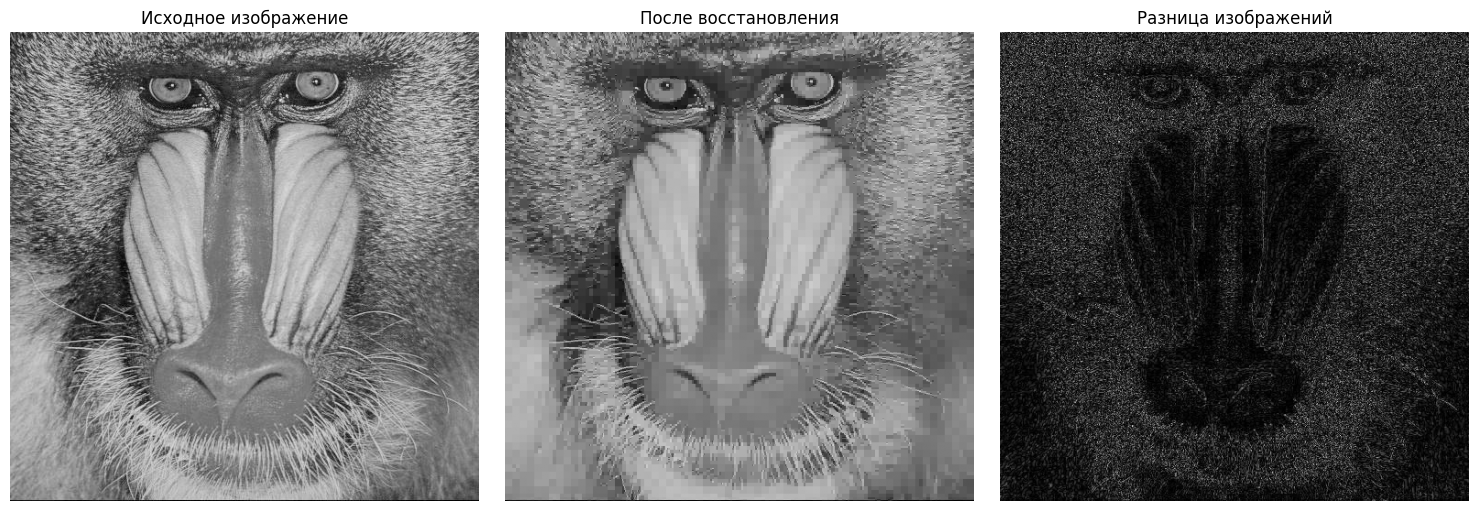

In [42]:
#Сравнение
mse = np.mean((img - restored.astype(np.float32)) ** 2)

if mse == 0:
    psnr = float('inf')
else:
    psnr = 10 * np.log10(255 ** 2 / mse)

print('MSE:', round(mse, 2))
print('PSNR:', round(psnr, 2), 'дБ')

diff = cv.absdiff(img.astype(np.uint8), restored)

plt.figure(figsize=(15, 5))

plt.subplot(131)
plt.imshow(img, cmap='gray', vmin=0, vmax=255)
plt.title('Исходное изображение')
plt.axis('off')

plt.subplot(132)
plt.imshow(restored, cmap='gray', vmin=0, vmax=255)
plt.title('После восстановления')
plt.axis('off')

plt.subplot(133)
plt.imshow(diff, cmap='gray')
plt.title('Разница изображений')
plt.axis('off')

plt.tight_layout()
plt.show()
